In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

dataFrame = pd.read_csv('course_lead_scoring_2026_hw4.csv')

# substitute NA / 0 for non existent values
numeric_cols = dataFrame.select_dtypes(include="number").columns
numeric_cols = numeric_cols.drop('converted')
string_cols = dataFrame.select_dtypes(include=["object", "string"]).columns
display(numeric_cols)
display("null numeric columns :" + str(dataFrame[numeric_cols].isnull().sum()))
display(string_cols)
display("null string columns :" + str(dataFrame[string_cols].isnull().sum()))
dataFrame[numeric_cols] = dataFrame[numeric_cols].fillna(0)
dataFrame[string_cols] = dataFrame[string_cols].fillna("NA")
display("after fixed null numeric columns :" + str(dataFrame[numeric_cols].isnull().sum()))
display("after fixed null string columns :" + str(dataFrame[string_cols].isnull().sum()))

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')

'null numeric columns :annual_income               369\nnumber_of_courses_viewed      0\ninteraction_count             0\nlead_score                   35\ndtype: int64'

Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str')

'null string columns :lead_source          148\nindustry             240\nemployment_status    194\nlocation             208\ndtype: int64'

'after fixed null numeric columns :annual_income               0\nnumber_of_courses_viewed    0\ninteraction_count           0\nlead_score                  0\ndtype: int64'

'after fixed null string columns :lead_source          0\nindustry             0\nemployment_status    0\nlocation             0\ndtype: int64'

In [4]:
df_full_train, df_test = train_test_split(dataFrame, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_full_train_actual = df_full_train['converted']
y_train_actual = df_train['converted']
y_val_actual = df_val['converted']
y_test_actual = df_test['converted']


In [5]:
# 1. ROC AUC feature importance - Receiver Operating Characteristic (ROC)
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

#For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
for col in numeric_cols:
    auc = roc_auc_score(y_train_actual, df_train[col])
    #If your AUC is < 0.5, invert this variable by putting "-" in front
    if auc < 0.5:
        df_train[col] = -df_train[col]
        auc = roc_auc_score(y_train_actual, df_train[col])

    print(f'AUC for {col}: {auc:.2f}')



AUC for annual_income: 0.61
AUC for number_of_courses_viewed: 0.72
AUC for interaction_count: 0.76
AUC for lead_score: 0.79


In [25]:
#2: Training the model

#Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

df_train_dicts = df_train.drop(columns=['converted']).to_dict(orient='records')

def train(dicts, Y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, Y)
    return model, dv

def predict(model, dv, dicts):
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

model, dv = train(df_train_dicts, y_train_actual) 

#AUC of this model on the validation dataset? (round to 3 digits)
from sklearn.metrics import roc_auc_score
x_val_dicts = df_val.drop(columns=['converted']).to_dict(orient='records')
y_val_pred = predict(model, dv, x_val_dicts)
auc = roc_auc_score(y_val_actual, y_val_pred)
print(round(auc, 3))

0.732


Precision and Recall are equal at threshold 0.97: 0.0
Precision and Recall are equal at threshold 0.98: 0.0
Precision and Recall are equal at threshold 0.99: 0.0
Minimum difference between precision and recall is 0.007502647993409384 at threshold 0.63


/workspaces/ml_hw1/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/workspaces/ml_hw1/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/workspaces/ml_hw1/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


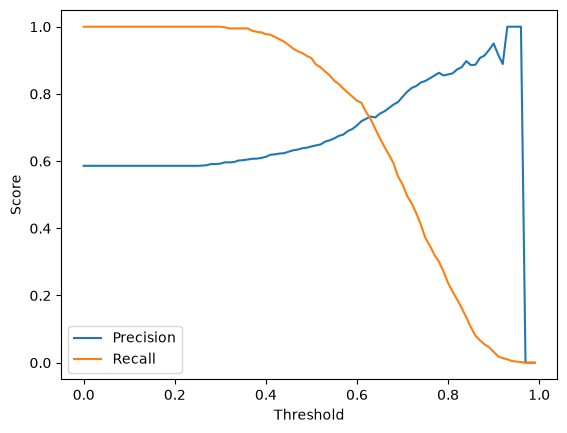

In [26]:
#3: Precision and Recall
'''Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
For each threshold, compute precision and recall
Plot them'''

from matplotlib import pyplot as plt
from sklearn.metrics import precision_score, recall_score

precisions = []
recalls = []
min_diff = 1
min_threshold = 0
threshold = np.arange(0.0 ,1.0, 0.01)
for t in threshold:
    y_val_pred_label = (y_val_pred >= t).astype(int)
    precisions.append(precision_score(y_val_actual, y_val_pred_label))
    recalls.append(recall_score(y_val_actual, y_val_pred_label))
    if precisions[-1] == recalls[-1]:
        #ignore this if diff values are 0
        print(f"Precision and Recall are equal at threshold {t}: {precisions[-1]}")
    else:
        diff = abs(precisions[-1] - recalls[-1])
        if diff < min_diff:
            min_diff = diff
            min_threshold = t


print(f"Minimum difference between precision and recall is {min_diff} at threshold {min_threshold}")
plt.plot(threshold, precisions, label='Precision')
plt.plot(threshold, recalls, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [27]:
#4. F1 score
''' F1 = 2 * (precision * recall) / (precision + recall) '''
from sklearn.metrics import f1_score


f1_scores = []
max_f1 = 0
best_threshold = 0
for t in threshold:
    y_val_pred_label = (y_val_pred >= t).astype(int)
    f1_scores.append(f1_score(y_val_actual, y_val_pred_label))
    if f1_scores[-1] > max_f1:
        max_f1 = f1_scores[-1]
        best_threshold = t

print(f"Maximum F1 score is {max_f1} at threshold {best_threshold}")


Maximum F1 score is 0.7576158940397351 at threshold 0.41000000000000003


In [28]:
#5. 5-Fold CV standard deviation

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
for train_index, val_index in kf.split(df_full_train):
    kf_df_train_dict = df_full_train.iloc[train_index].drop(columns=['converted']).to_dict(orient="records")
    kf_df_val_dict = df_full_train.iloc[val_index].drop(columns=['converted']).to_dict(orient="records")
    model, dv = train(kf_df_train_dict, y_full_train_actual.iloc[train_index])
    y_pred = predict( model, dv, kf_df_val_dict)

    auc = roc_auc_score(y_full_train_actual.iloc[val_index], y_pred)
    scores.append(auc)

cv_scores = np.array(scores)
print(f"5-fold ROC AUC scores: {np.round(cv_scores, 3)}")
print(f"Standard deviation: {cv_scores.std():.3f}")

#alternate sklearn cross-validation with pipeline
cv_model = make_pipeline(DictVectorizer(sparse=False), LogisticRegression(**model.get_params()))
full_train_dicts = df_full_train.drop(columns=['converted']).to_dict(orient='records')
cv_scores_builtin = cross_val_score(cv_model, full_train_dicts, y_full_train_actual, cv=kf, scoring="roc_auc", error_score='raise')
print(f"5-fold ROC AUC scores (builtin): {cv_scores_builtin}")
print(f"Standard deviation (builtin): {cv_scores_builtin.std():.3f}")

5-fold ROC AUC scores: [0.731 0.73  0.736 0.741 0.721]
Standard deviation: 0.007
5-fold ROC AUC scores (builtin): [0.7305601  0.72957261 0.73634281 0.74124547 0.72091386]
Standard deviation (builtin): 0.007


In [36]:
# 6. Find the best regularization parameter C using 5-fold ROC AUC
c_values = [0.000001, 0.001, 1]
c_scores_std = {}

#mean ROC AUC for each C using 5-fold cross-validation
for c in c_values:
    scores = []
    for train_index, val_index in kf.split(df_full_train):
        kf_df_train_dict = df_full_train.iloc[train_index].drop(columns=['converted']).to_dict(orient="records")
        kf_df_val_dict = df_full_train.iloc[val_index].drop(columns=['converted']).to_dict(orient="records")
        model, dv = train(kf_df_train_dict, y_full_train_actual.iloc[train_index], C=c)
        y_pred = predict( model, dv, kf_df_val_dict)

        auc = roc_auc_score(y_full_train_actual.iloc[val_index], y_pred)
        scores.append(auc)
    #Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    c_scores_std[c] = std_auc
    print(f"C={c}: mean ROC AUC={mean_auc:.3f}, std ROC AUC={std_auc:.3f}")


#alternate buildin way
c_scores_builtin = {}
for c in c_values:
    cv_model = make_pipeline(
        DictVectorizer(sparse=False),
        LogisticRegression(solver="liblinear", C=c, max_iter=1000)
    )
    scores = cross_val_score(
        cv_model,
        full_train_dicts,
        y_full_train_actual,
        cv=kf,
        scoring="roc_auc"
    )
    c_scores_builtin[c] = scores.mean()


best_C = max(c_scores_builtin, key=c_scores_builtin.get)
print(f"Best C: {best_C} (mean ROC AUC={c_scores_builtin[best_C]:.3f})")

C=1e-06: mean ROC AUC=0.617, std ROC AUC=0.019
C=0.001: mean ROC AUC=0.749, std ROC AUC=0.010
C=1: mean ROC AUC=0.732, std ROC AUC=0.007
Best C: 0.001 (mean ROC AUC=0.749)
